In [1]:
!nvidia-smi

Thu Oct  8 22:08:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.9 MB/s eta 0:00:00


In [3]:
from google.colab import drive

drive.mount("/content/drive")
!unzip -q /content/drive/MyDrive/football-analytics/football_dataset_v1.zip -d /content/data

Mounted at /content/drive


In [4]:
import ultralytics
from pathlib import Path

ultralytics.checks()

root = Path("/content/data/football")
for sp in ["train", "valid", "test"]:
    print(sp, len(list((root / sp / "images").glob("*.jpg"))))
print((root / "data.yaml").read_text())

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 43.1/112.6 GB disk)
train 1630
valid 275
test 298
path: /content/data/football
train: train/images
val: valid/images
test: test/images
names:
  0: ball
  1: goalkeeper
  2: player
  3: referee



In [5]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
results = model.train(
    data="/content/data/football/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    seed=0,
    workers=2,
    project="/content/drive/MyDrive/football-analytics/runs",
    name="baseline_yolo26n_640",
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/football/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolo26n_640, nbs=64, nms=None, opset=None, optim

(np.float64(-0.5), np.float64(2999.5), np.float64(2249.5), np.float64(-0.5))

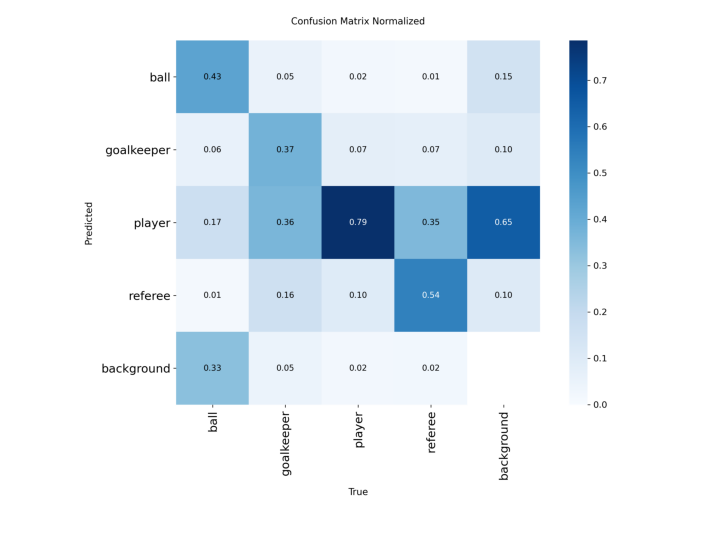

In [6]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

run = Path("/content/drive/MyDrive/football-analytics/runs/baseline_yolo26n_640")

plt.figure(figsize=(9, 8))
plt.imshow(mpimg.imread(run / "confusion_matrix_normalized.png"))
plt.axis("off")

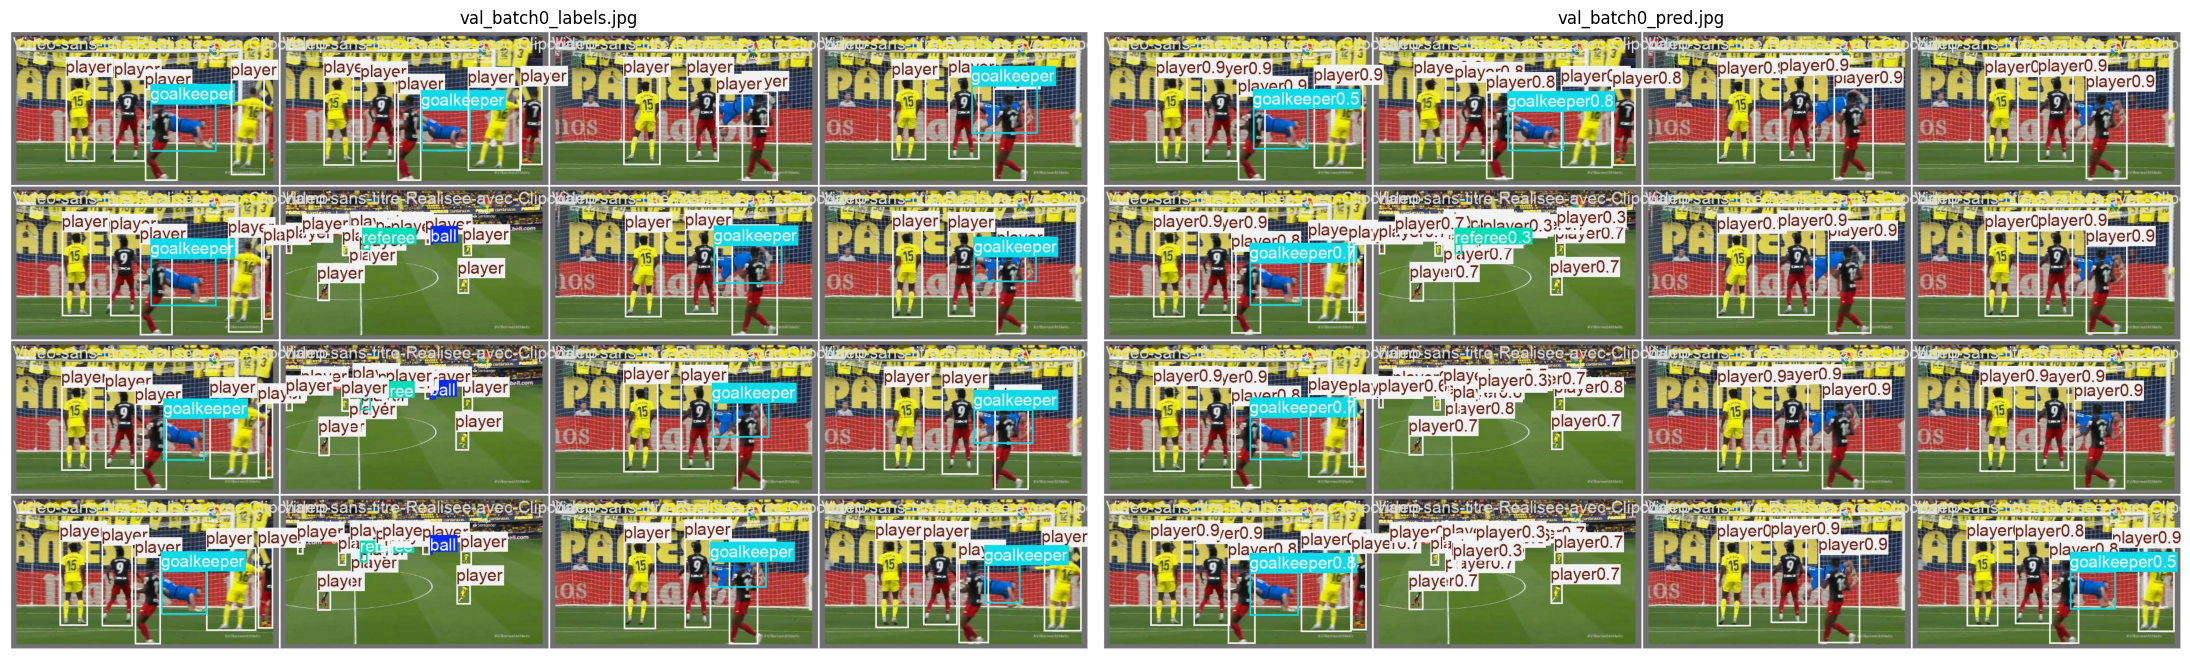

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, name in zip(axes, ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]):
    ax.imshow(mpimg.imread(run / name))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()

In [8]:
import numpy as np
from collections import Counter
from PIL import Image

train_dir = Path("/content/data/football/train")
print(Counter(Image.open(p).size for p in (train_dir / "images").glob("*.jpg")).most_common(5))

widths, heights = [], []
for f in (train_dir / "labels").glob("*.txt"):
    w, h = Image.open(train_dir / "images" / (f.stem + ".jpg")).size
    for line in f.read_text().splitlines():
        c, x, y, bw, bh = line.split()[:5]
        if c == "0":
            widths.append(float(bw) * w)
            heights.append(float(bh) * h)

widths, heights = np.array(widths), np.array(heights)
print("ball boxes:", len(widths))
print("median ball size (px, native):", np.median(widths), np.median(heights))
print("ball boxes narrower than 16 px:", (widths < 16).mean())

[((1920, 1080), 1630)]
ball boxes: 1424
median ball size (px, native): 23.875 24.0
ball boxes narrower than 16 px: 0.07092696629213484


In [9]:
model = YOLO("yolo26n.pt")
results = model.train(
    data="/content/data/football/data.yaml",
    epochs=30,
    imgsz=1280,
    batch=8,
    seed=0,
    workers=2,
    project="/content/drive/MyDrive/football-analytics/runs",
    name="yolo26n_1280",
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/football/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_1280, nbs=64, nms=None, opset=None, optimize=Fals